# 16 — exp1 boundary check: the requirement where it is decided

30 CNS combinations whose predicted worst case over the heading is closest to 1e-3 (at most 2 per category), each simulated at its predicted worst heading with 10^6 encounters (10x the campaign) and at the other end of the heading range with 10^5, on encounter streams independent of the campaign (seed 8). Results cached in `results/exp1_boundary_worst.jsonl` and `..._other.jsonl` (resumable).

In [1]:
import os
os.environ.setdefault("TRC_N_JOBS", "100")              # at most 100 workers on ATO
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[v] = "1"                                  # one thread per worker
import json
import sys
import time
from pathlib import Path
from unittest import mock

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from mvlse import fit_surrogate

sys.path.insert(0, str(Path.cwd().parent))
import common
import config
import sim

P = config.EXPERIMENTS["exp1_heading"]
space = config.space_of(P["space"])
TAU = config.TAU
TEST_SEED = config.SEED + 1          # encounter streams independent of the campaign's (seed 7)
STORE = Path.cwd().parent / "results" / "exp1_heading" / "campaign" / "store.jsonl"
train = [json.loads(line) for line in STORE.read_text().splitlines() if line.strip()]
w_train = space.encode([r["point"] for r in train])
y_train = np.array([r["y"] for r in train])
model = fit_surrogate(config.LSE["method"], space, w_train, y_train, correlation=config.LSE["correlation"],
                      rng=np.random.default_rng(config.SEED), n_starts=12)      # as notebook 11
print(f"surrogate refitted on the {len(train)} exp1 samples; workers: {config.N_JOBS}; test seed {TEST_SEED}")
print(common.code_state())


def floor(n):
    return np.log10(0.5 / (n + 1.0))


def mc_interval(y, n):
    """Measured P(LoS) and its 95% Jeffreys interval, from (y, n) as the simulator reports it."""
    k = max(0, int(round(10 ** y * (n + 1.0) - 0.5)))
    lo = 0.0 if k == 0 else stats.beta.ppf(0.025, k + 0.5, n - k + 0.5)
    hi = stats.beta.ppf(0.975, k + 0.5, n - k + 0.5)
    return k, k / n, lo, hi


def se_log(y, n):
    """Delta-method standard error of y = log10 P_hat (as blueskycdarr reports it)."""
    p = 10 ** y
    return np.sqrt((1.0 - p) / (n * p)) / np.log(10.0)


def run_points(points, n, cache, tag):
    """Simulate each point (one at a time, all workers on its encounters), cached line by line,
    so an interrupted run resumes where it stopped."""
    done = {}
    if cache.exists():
        for line in cache.read_text().splitlines():
            r = json.loads(line)
            done[r["id"]] = r
    todo = [(i, p) for i, p in enumerate(points) if i not in done]
    print(f"{tag}: {len(done)} of {len(points)} cached, {len(todo)} to run at N = {n:.0e}", flush=True)
    with mock.patch.object(config, "SEED", TEST_SEED):
        evaluate = sim.blackbox(n_encounters=n)
    t0 = time.perf_counter()
    for i, p in todo:
        t = time.perf_counter()
        y = float(evaluate([p])[0])
        rec = {"id": i, "point": p, "y": y, "n": n, "seed": TEST_SEED, "seconds": time.perf_counter() - t}
        with cache.open("a") as fh:
            fh.write(json.dumps(rec) + "\n")
        done[i] = rec
        print(f"[{(time.perf_counter() - t0) / 60:6.1f} min] {tag} {i:3d}: {common.show_p(y, n)}", flush=True)
    return [done[i] for i in range(len(points))]

surrogate refitted on the 250 exp1 samples; workers: 100; test seed 8
{'mvlse': {'commit': 'd2c7f3b15111e48ffeb9e62af873476b44a02444', 'dirty': True}, 'blueskycdarr': {'commit': '030c0f459a3c5491cef88485e2672aef60a14179', 'dirty': False}}


In [2]:
# Worst case over heading from the surrogate, on the same grid as notebook 11: 41 x 41 (reception,
# range) per category, 37 headings. Pick the designs whose predicted worst case is closest to 1e-3,
# at most 2 per category, 30 in all.
N_P, N_R, N_PSI = 41, 41, 37
gp_, gr_ = np.meshgrid(np.linspace(0, 1, N_P), np.linspace(0, 1, N_R), indexing="ij")
psi_u = np.linspace(0, 1, N_PSI)
rows = []
for cat in space.categories:
    d = np.column_stack([gp_.ravel(), gr_.ravel()])
    wq = np.column_stack([np.repeat(d, N_PSI, axis=0), np.tile(psi_u, len(d)),
                          np.tile(np.array(cat, float), (len(d) * N_PSI, 1))])
    mu, s = model.predict(wq)
    mu, s = mu.reshape(len(d), N_PSI), s.reshape(len(d), N_PSI)
    iw = mu.argmax(axis=1)
    for i in range(len(d)):
        rows.append({"category": cat, "p_u": d[i, 0], "r_u": d[i, 1], "psi_worst_u": psi_u[iw[i]],
                     "mu_worst": mu[i, iw[i]], "s_worst": s[i, iw[i]], "mu_2": mu[i, 0], "mu_180": mu[i, -1]})
grid = pd.DataFrame(rows)
grid["gap"] = (grid.mu_worst - TAU).abs()
picked, used = [], {}
for _, r in grid.sort_values("gap").iterrows():
    if used.get(r.category, 0) >= 2:
        continue
    if any(r.category == q.category and abs(r.p_u - q.p_u) + abs(r.r_u - q.r_u) < 0.15 for q in picked):
        continue                                     # two picks in a category must be apart
    picked.append(r); used[r.category] = used.get(r.category, 0) + 1
    if len(picked) == 30:
        break
sel = pd.DataFrame(picked).reset_index(drop=True)

def to_point(r, psi_u):
    w = np.array([[r.p_u, r.r_u, psi_u, *r.category]], float)
    return {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in space.decode(w)[0].items()}

worst_points = [to_point(r, r.psi_worst_u) for r in sel.itertuples()]
other_points = [to_point(r, 1.0 if r.psi_worst_u < 0.5 else 0.0) for r in sel.itertuples()]   # the other end
show = pd.DataFrame(worst_points).assign(speed_kt=lambda d: (d.speed / config.KT).round().astype(int),
                                         predicted=[f"{10 ** m:.1e}" for m in sel.mu_worst],
                                         other_end=[p["dpsi"] for p in other_points])
show[["speed_kt", "vel_ci95", "pos_ci95", "p_reception", "max_range_m", "dpsi", "other_end", "predicted"]].round(2)

,speed_kt,vel_ci95,pos_ci95,p_reception,max_range_m,dpsi,other_end,predicted
0,20,3.0,10.0,0.37,10222.5,2.00,180.0,1.0e-03
1,20,3.0,30.0,0.26,12795.0,2.00,180.0,1.0e-03
2,40,3.0,3.0,0.19,13530.0,2.00,180.0,1.0e-03
3,20,3.0,30.0,0.46,667.5,180.00,2.0,1.0e-03
4,20,3.0,92.6,0.37,1035.0,2.00,180.0,1.0e-03
5,40,3.0,30.0,0.12,5077.5,2.00,180.0,1.0e-03
6,20,3.0,92.6,0.53,667.5,180.00,2.0,1.0e-03
7,60,3.0,10.0,0.17,8385.0,66.28,180.0,1.0e-03
8,20,3.0,10.0,0.50,10590.0,2.00,180.0,1.0e-03
9,60,3.0,30.0,0.17,10222.5,180.00,2.0,1.0e-03


In [3]:
# Each design at its predicted worst heading with 10^6 encounters (10x the campaign), and at the other
# end of the heading range with 10^5 (is the predicted worst heading really the worse end?).
N_WORST, N_OTHER = 10 * config.N_ENCOUNTERS, config.N_ENCOUNTERS
res_worst = run_points(worst_points, N_WORST, Path("results/exp1_boundary_worst.jsonl"), "worst")
res_other = run_points(other_points, N_OTHER, Path("results/exp1_boundary_other.jsonl"), "other end")

worst: 0 of 30 cached, 30 to run at N = 1e+06


[   6.7 min] worst   0: P(LoS) = 2.90e-03  95% CI [2.8e-03, 3.0e-03]


[  13.4 min] worst   1: P(LoS) = 6.33e-03  95% CI [6.2e-03, 6.5e-03]


[  22.8 min] worst   2: P(LoS) = 3.62e-03  95% CI [3.5e-03, 3.7e-03]


[  29.7 min] worst   3: P(LoS) = 3.05e-05  95% CI [2.1e-05, 4.3e-05]


[  37.2 min] worst   4: P(LoS) = 2.50e-03  95% CI [2.4e-03, 2.6e-03]


... (52 outputs left out)

[  34.1 min] other end  26: P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)


[  35.9 min] other end  27: P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)


[  36.6 min] other end  28: P(LoS) = 5.35e-03  95% CI [4.9e-03, 5.8e-03]


[  38.4 min] other end  29: P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)


In [4]:
out = []
for r, a, b in zip(sel.itertuples(), res_worst, res_other):
    k, p_hat, lo, hi = mc_interval(a["y"], N_WORST)
    k2, p2, lo2, hi2 = mc_interval(b["y"], N_OTHER)
    pred_ok = r.mu_worst <= TAU
    out.append({
        "speed_kt": round(a["point"]["speed"] / config.KT), "vel": a["point"]["vel_ci95"], "pos": a["point"]["pos_ci95"],
        "p": a["point"]["p_reception"], "R_km": a["point"]["max_range_m"] / 1e3, "worst dpsi": a["point"]["dpsi"],
        "predicted": 10 ** r.mu_worst, "pred 95% lo": 10 ** (r.mu_worst - 1.96 * r.s_worst),
        "pred 95% hi": 10 ** (r.mu_worst + 1.96 * r.s_worst),
        "measured": p_hat, "meas 95% lo": lo, "meas 95% hi": hi, "losses": k,
        "predicted acceptable": pred_ok,
        "measured acceptable": p_hat <= 1e-3,
        "clearly wrong side": (pred_ok and lo > 1e-3) or (not pred_ok and hi < 1e-3),
        "inside pred 95%": (10 ** (r.mu_worst - 1.96 * r.s_worst) <= p_hat <= 10 ** (r.mu_worst + 1.96 * r.s_worst)),
        "other end dpsi": b["point"]["dpsi"], "other end measured": p2,
        "worst end not contradicted": hi >= lo2,     # the other end is not clearly worse
    })
conf = pd.DataFrame(out)
conf.to_csv("results/exp1_boundary_check.csv", index=False)
summary = {
    "designs": len(conf),
    "measured on the predicted side of 1e-3": f"{(conf['predicted acceptable'] == conf['measured acceptable']).mean():.0%}",
    "clearly on the wrong side (95% MC interval excludes 1e-3)": int(conf["clearly wrong side"].sum()),
    "measured inside the surrogate's 95% interval": f"{conf['inside pred 95%'].mean():.0%}",
    "predicted acceptable but measured not": int((conf["predicted acceptable"] & ~conf["measured acceptable"]).sum()),
    "other end not clearly worse than the predicted worst": f"{conf['worst end not contradicted'].mean():.0%}",
}
display(pd.Series(summary, name="boundary check").to_frame())
conf.round(4)

,boundary check
designs,30
measured on the predicted side of 1e-3,63%
clearly on the wrong side (95% MC interval excludes 1e-3),11
measured inside the surrogate's 95% interval,53%
predicted acceptable but measured not,8
other end not clearly worse than the predicted worst,73%


,speed_kt,vel,pos,p,R_km,worst dpsi,predicted,pred 95% lo,pred 95% hi,measured,meas 95% lo,meas 95% hi,losses,predicted acceptable,measured acceptable,clearly wrong side,inside pred 95%,other end dpsi,other end measured,worst end not contradicted
0,20,3.0,10.0,0.3700,10.2225,2.0000,0.001,0.0001,0.0089,0.0029,0.0028,0.0030,2904,True,False,True,True,180.0,0.0000,True
1,20,3.0,30.0,0.2575,12.7950,2.0000,0.001,0.0002,0.0064,0.0063,0.0062,0.0065,6326,False,False,False,True,180.0,0.0001,True
2,40,3.0,3.0,0.1900,13.5300,2.0000,0.001,0.0002,0.0045,0.0036,0.0035,0.0037,3617,True,False,True,True,180.0,0.0003,True
3,20,3.0,30.0,0.4600,0.6675,180.0000,0.001,0.0002,0.0054,0.0000,0.0000,0.0000,30,True,True,False,False,2.0,0.0016,False
4,20,3.0,92.6,0.3700,1.0350,2.0000,0.001,0.0001,0.0068,0.0025,0.0024,0.0026,2498,False,False,False,True,180.0,0.0000,True
5,40,3.0,30.0,0.1225,5.0775,2.0000,0.001,0.0001,0.0108,0.0133,0.0131,0.0136,13341,False,False,False,False,180.0,0.0008,True
6,20,3.0,92.6,0.5275,0.6675,180.0000,0.001,0.0001,0.0086,0.0005,0.0005,0.0006,512,True,True,False,True,2.0,0.0014,False
7,60,3.0,10.0,0.1675,8.3850,66.2778,0.001,0.0001,0.0087,0.0002,0.0002,0.0002,177,False,True,True,True,180.0,0.0006,False
8,20,3.0,10.0,0.5050,10.5900,2.0000,0.001,0.0002,0.0059,0.0014,0.0013,0.0014,1357,False,False,False,True,180.0,0.0000,True
9,60,3.0,30.0,0.1675,10.2225,180.0000,0.001,0.0001,0.0075,0.0002,0.0002,0.0002,189,True,True,False,True,2.0,0.0004,False


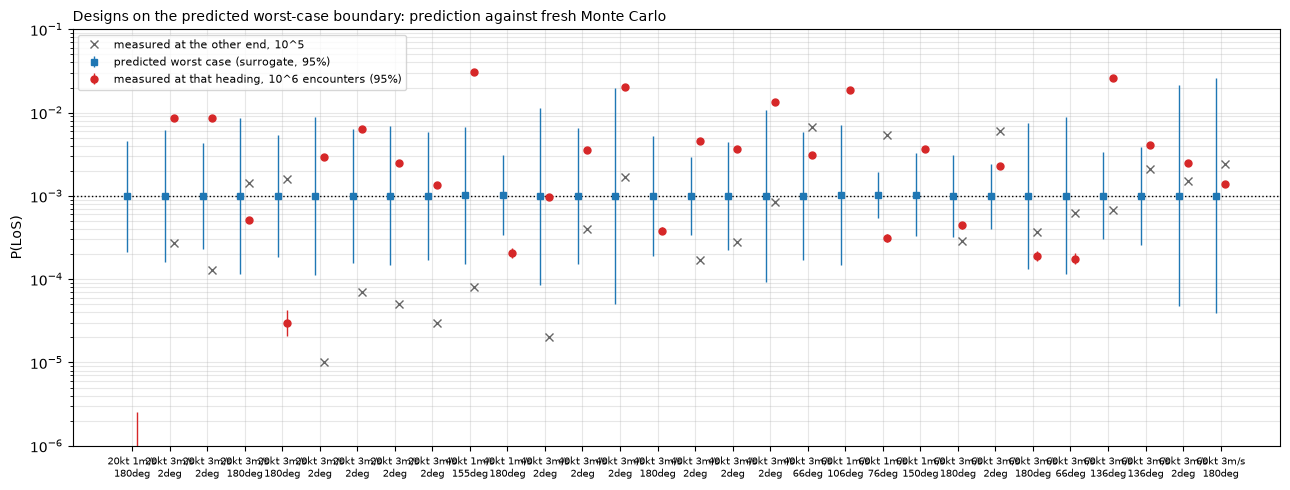

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))
order = conf.sort_values(["speed_kt", "vel", "predicted"]).index
x = np.arange(len(order))
c = conf.loc[order]
ax.errorbar(x - 0.12, c.predicted, yerr=[c.predicted - c["pred 95% lo"], c["pred 95% hi"] - c.predicted],
            fmt="s", color="C0", ms=5, elinewidth=1, label="predicted worst case (surrogate, 95%)")
ax.errorbar(x + 0.12, c.measured.clip(lower=1e-7), yerr=[c.measured.clip(lower=1e-7) - c["meas 95% lo"].clip(lower=1e-7),
            c["meas 95% hi"] - c.measured.clip(lower=1e-7)], fmt="o", color="C3", ms=5, elinewidth=1,
            label="measured at that heading, 10^6 encounters (95%)")
ax.plot(x + 0.12, c["other end measured"].clip(lower=1e-7), "x", color="0.4", ms=6, label="measured at the other end, 10^5")
ax.axhline(1e-3, color="k", ls=":", lw=1)
ax.set_yscale("log"); ax.set_ylim(1e-6, 1e-1)
ax.set_xticks(x, [f"{r.speed_kt}kt {r.vel:g}m/s\n{r['worst dpsi']:.0f}deg" for _, r in c.iterrows()], fontsize=7)
ax.set_ylabel("P(LoS)"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Designs on the predicted worst-case boundary: prediction against fresh Monte Carlo", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig("results/exp1_boundary_check.png", dpi=130); plt.show()

## Insight

**1. On the predicted boundary, the prediction is off by a factor of about 4 (median) and up to 30, and its interval is too narrow.**
- **What was predicted:** every one of the 30 designs at $P(\mathrm{LoS}) = 10^{-3}$, at its predicted worst heading.
- **What was measured** (at $10^6$ encounters): from no LoS at all to $3\times10^{-2}$.
- **Interval:** only 16 of 30 (53%) lie inside the surrogate's 95% interval.
- **Contrast with the hold-out (notebook 15):** there the interval covered every point and was cautious. Here, where the requirement is decided, it is overconfident.

**2. The error is systematic: the risk at shallow headings is underestimated.**
- **Predicted worst at 2°:** 13 of the 14 designs measure above $10^{-3}$, by a factor of 3.6 (median) and up to 20.
- **Predicted worst at 180°:** 7 of 8 measure below, by a factor of 3.4 (median).
- **Wrong end:** in 8 of 30 designs the other end of the heading range is clearly worse than the predicted worst heading, mostly where 180° was predicted and 2° turns out worse.
- **Likely cause:** $P(\mathrm{LoS})$ rises steeply towards the shallow end, faster than the smooth surrogate fitted to the few samples there can follow. The campaign put 49 of its 250 samples between 2° and 20°.

**3. The requirement read from exp1 is too lenient.**
- **Measured at the predicted worst heading:** 20 of the 30 boundary designs exceed $10^{-3}$.
- **Taking the worse of the two ends:** 23 of 30 exceed it.
- **Consequence:** the true acceptable region is smaller than the predicted one, with the reception floor at 3 m/s and the range floor higher than in Section 5.3.

**4. Velocity accuracy remains the deciding variable.** 24 of the 30 boundary designs are at 3 m/s, and the six at 1 m/s are all at short range (0.7–1.8 km). The boundary in the other variables is what the surrogate gets wrong, not the conclusion that 10 m/s is never acceptable.